# Variance Reduction: CUPED and Regression Adjustment

**What you'll learn**

- Why variance reduction is the highest-leverage engineering you can do on an experiment
  platform: cutting metric variance by a factor $f$ cuts required traffic/time by the same
  $f$ at unchanged $\alpha$, power, and MDE — and we quantify that in days and experiment
  throughput on a concrete baseline experiment.
- CUPED from first principles: derive $\theta^* = \mathrm{cov}(Y, X)/\mathrm{var}(X)$,
  see why a **pre-experiment** covariate leaves the estimate unbiased, and implement it on
  realistic zero-inflated, heavy-tailed user spend data with a ~44% variance reduction.
- The exact relationship to regression adjustment (ANCOVA): numerically near-identical
  estimates and SEs, multiple covariates via OLS, and CUPAC — an ML-predicted covariate —
  with a cross-fitted LightGBM demo.
- Where CUPED shines vs does nothing: the $\rho^2$ rule, pre-period window length,
  new users with no history, and how to handle mixed populations with stratified CUPED.
- Post-stratification implemented and benchmarked against CUPED, and why binary metrics
  only ever get modest help (a variance-decomposition argument, then numbers).
- The classic production bug — using an *in-experiment* covariate — demonstrated by
  replication: it shrinks variance *and* silently biases the estimate.

**Why it matters in interviews**

- "Our experiments take six weeks; how would you speed them up?" is a canonical senior
  experimentation question. The expected answer is CUPED/regression adjustment *with
  numbers*: reduction = $\rho^2$, traffic multiplier = $1/(1-\rho^2)$.
- "Why must the covariate be pre-experiment?" tests causal reasoning (conditioning on a
  post-treatment variable), not memorization. We show the failure in code.
- "CUPED vs just adding covariates to a regression?" separates people who have built or
  used experiment platforms from people who have read a blog post — the answer is "same
  estimator, different operational packaging".
- Case rounds love "how much money does variance reduction save?" — there is a clean
  quantitative answer you should be able to sketch on a whiteboard.

Sizing machinery (power, MDE, the rule of 16) lives in
[02_power_mde_sample_size.ipynb](./02_power_mde_sample_size.ipynb) and the end-to-end
analysis workflow in [01_ab_test_end_to_end.ipynb](./01_ab_test_end_to_end.ipynb).
Sequential monitoring is [04_peeking_sequential.ipynb](./04_peeking_sequential.ipynb),
ratio metrics and clustered data
[05_ratio_metrics_delta_method.ipynb](./05_ratio_metrics_delta_method.ipynb), and the
theory of good vs bad controls
[../03_causal_inference/01_potential_outcomes_dags.ipynb](../03_causal_inference/01_potential_outcomes_dags.ipynb).

In [1]:
import numpy as np
import pandas as pd
import scipy.stats as st
import statsmodels.api as sm
import matplotlib.pyplot as plt
from lightgbm import LGBMRegressor
from sklearn.model_selection import KFold

rng = np.random.default_rng(42)

plt.rcParams.update({
    "figure.figsize": (9, 4.2),
    "axes.grid": True,
    "grid.alpha": 0.3,
    "axes.titlesize": 11,
    "figure.constrained_layout.use": True,
})
pd.set_option("display.width", 130)

Z = st.norm


def dim(y, t):
    """Difference in means (treated - control) with unpooled (Welch) SE."""
    y1, y0 = y[t == 1], y[t == 0]
    est = y1.mean() - y0.mean()
    se = np.sqrt(y1.var(ddof=1) / y1.size + y0.var(ddof=1) / y0.size)
    return est, se


def ci_p(est, se):
    """95% normal CI and two-sided p-value."""
    return est - 1.96 * se, est + 1.96 * se, 2 * Z.sf(abs(est) / se)


def cuped_adjust(y, x):
    """CUPED-adjusted metric with pooled theta. Returns (y_cv, theta)."""
    theta = np.cov(y, x, ddof=1)[0, 1] / np.var(x, ddof=1)
    return y - theta * (x - x.mean()), theta


def n_per_arm(sd, delta, alpha=0.05, power=0.80):
    """Per-arm n for a two-arm difference in means (normal approximation)."""
    z = Z.ppf(1 - alpha / 2) + Z.ppf(power)
    return 2 * (z * sd / delta) ** 2


def mde_abs(sd, n_arm, alpha=0.05, power=0.80):
    """Absolute MDE at a given per-arm n."""
    z = Z.ppf(1 - alpha / 2) + Z.ppf(power)
    return z * sd * np.sqrt(2 / n_arm)

## 1. Why variance reduction is money

From the rule of 16 ([02_power_mde_sample_size.ipynb](./02_power_mde_sample_size.ipynb)):

$$n_{\text{per arm}} \approx \frac{16\,\sigma^2}{\delta^2}.$$

Every term is a business constraint except $\sigma^2$. The MDE $\delta$ is set by what is
worth shipping, $\alpha$ and power by your error tolerance — but the *variance of the
metric* is an engineering artifact. If you can build a metric $Y^{cv}$ that has the **same
expected treatment difference** but variance $(1-\rho^2)\,\sigma^2$, then at fixed MDE you
need $(1-\rho^2)\times$ the traffic, i.e. the experiment finishes in $(1-\rho^2)\times$
the calendar time. Equivalently, at fixed duration your MDE shrinks by
$\sqrt{1-\rho^2}$. That multiplier applies to *every experiment the platform runs,
forever* — which is why every mature platform (Microsoft, Netflix, Airbnb, Booking,
DoorDash) runs some form of it by default.

**The baseline experiment** we will improve throughout: a marketplace tests a new checkout
flow. Primary metric: 2-week revenue per user. About 15,000 eligible users/day enter the
experiment, split 50/50. Spend is zero-inflated (~60% of users buy nothing in a window)
and heavy-tailed. We simulate 200,000 users with a **known true effect of +2%** on
revenue per user, and — crucially for CUPED — each user also has a *pre-experiment*
2-week spend, correlated with in-experiment spend because user behavior is persistent
(habitual buyers keep buying, whales stay whales).

In [2]:
def gen_arrays(n, rel_effect, rng, sticky=0.6):
    """Marketplace users with persistent heterogeneity.

    Latents: purchase propensity pi (persistent habit) and typical order value mu
    (heavy-tailed). Pre-period and in-experiment spend share (pi, mu), plus 'sticky'
    persistence of purchase incidence, giving a realistic pre/post correlation.
    Treatment multiplies in-experiment spend by (1 + rel_effect); it also lifts
    in-experiment sessions by 5% (used later to demo the classic CUPED bug).
    """
    pi = rng.beta(0.8, 1.2, n)                       # purchase propensity, mean 0.40
    mu = rng.lognormal(3.0, 0.8, n)                  # typical order value | purchase
    tenure = rng.gamma(2.0, 150.0 * (0.5 + pi))      # days since signup (habit correlates)
    sessions_pre = rng.poisson(2.0 + 25.0 * pi)      # pre-period visits: signal even at $0 spend
    buy_pre = rng.random(n) < pi
    buy_exp = np.where(rng.random(n) < sticky, buy_pre, rng.random(n) < pi)
    spend_pre = np.where(buy_pre, mu * rng.gamma(6.0, 1 / 6.0, n), 0.0)
    t = rng.permutation(np.arange(n) % 2)            # exact 50/50 randomization
    y = np.where(buy_exp, mu * rng.gamma(6.0, 1 / 6.0, n), 0.0) * (1 + rel_effect * t)
    sessions_exp = rng.poisson((2.0 + 25.0 * pi) * (1 + 0.05 * t))
    return dict(treatment=t, tenure_days=tenure, sessions_pre=sessions_pre,
                spend_pre=spend_pre, spend_exp=y, sessions_exp=sessions_exp, pi=pi, mu=mu)


# Ground truth (analytic): E[Y | control] = E[pi] * E[mu] = 0.4 * exp(3 + 0.8^2/2)
TRUE_CTRL_MEAN = 0.4 * np.exp(3.0 + 0.8**2 / 2)
REL_EFFECT = 0.02
TRUE_ATE = REL_EFFECT * TRUE_CTRL_MEAN
N_USERS, DAILY_USERS = 200_000, 15_000

raw = gen_arrays(N_USERS, REL_EFFECT, rng)
df = pd.DataFrame({k: v for k, v in raw.items() if k not in ("pi", "mu")})  # observables only

y = df["spend_exp"].to_numpy()
x = df["spend_pre"].to_numpy()
t = df["treatment"].to_numpy()

print(df.head(5).round(2).to_string())
print(f"\nusers: {N_USERS:,}  |  treated share: {t.mean():.3f}")
print(f"revenue/user (control): mean ${y[t == 0].mean():.2f}, sd ${y[t == 0].std(ddof=1):.1f}, "
      f"p99 ${np.quantile(y, 0.99):.0f}, zero share {np.mean(y == 0):.1%}")
print(f"pre/post correlation rho(spend_pre, spend_exp) = {np.corrcoef(x, y)[0, 1]:.3f}")
print(f"true ATE = {REL_EFFECT:.0%} x ${TRUE_CTRL_MEAN:.2f} = ${TRUE_ATE:.3f} per user")

   treatment  tenure_days  sessions_pre  spend_pre  spend_exp  sessions_exp
0          0       225.03            14       0.00       0.00            15
1          1        72.62             5       0.00       0.00             4
2          0       278.96             1       0.00       0.00             0
3          0       387.12            10      25.05      29.67            16
4          1       244.42            12       0.00       0.00            11

users: 200,000  |  treated share: 0.500
revenue/user (control): mean $11.09, sd $23.3, p99 $107, zero share 59.9%
pre/post correlation rho(spend_pre, spend_exp) = 0.665
true ATE = 2% x $11.06 = $0.221 per user


### The baseline readout and what it costs

First the standard analysis (Welch-style two-sample comparison, as in
[01_ab_test_end_to_end.ipynb](./01_ab_test_end_to_end.ipynb)), then what detecting a 2%
lift with 80% power costs in traffic and calendar time *without* any variance reduction.

In [3]:
est0, se0 = dim(y, t)
lo0, hi0, p0 = ci_p(est0, se0)
ctrl_mean = y[t == 0].mean()
sd_y = y.std(ddof=1)

delta_target = 0.02 * ctrl_mean                    # MDE: 2% relative
n_arm_base = n_per_arm(sd_y, delta_target)
days_base = 2 * n_arm_base / DAILY_USERS

print("Baseline readout (difference in means)")
print(f"  estimate  ${est0:.3f}  ({est0 / ctrl_mean:+.2%} relative)   truth ${TRUE_ATE:.3f}")
print(f"  95% CI    [${lo0:.3f}, ${hi0:.3f}]   width ${hi0 - lo0:.3f}")
print(f"  p-value   {p0:.4f}")
print("\nWhat 80% power at a 2% MDE costs without variance reduction:")
print(f"  n per arm {n_arm_base:,.0f}  ->  total {2 * n_arm_base:,.0f} users")
print(f"  at {DAILY_USERS:,} users/day: {days_base:.1f} days of full traffic")

Baseline readout (difference in means)
  estimate  $0.125  (+1.13% relative)   truth $0.221
  95% CI    [$-0.081, $0.332]   width $0.412
  p-value   0.2335

What 80% power at a 2% MDE costs without variance reduction:
  n per arm 176,584  ->  total 353,168 users
  at 15,000 users/day: 23.5 days of full traffic


A 2% lift on the primary revenue metric — a big deal for a marketplace — needs roughly
**three and a half weeks** of full traffic here. Worse, the readout on our 200k users
*misses* the true +2% effect entirely (p ≈ 0.23): at this variance, 200k users is an
underpowered experiment. This is the problem variance reduction attacks.

## 2. CUPED from first principles

**CUPED** (Controlled-experiment Using Pre-Experiment Data; Deng, Xu, Kohavi & Walker,
WSDM 2013) replaces the metric $Y$ with

$$Y^{cv} = Y - \theta\,(X - \bar X),$$

where $X$ is any covariate measured **before** the experiment started (here: the same
user's pre-period spend) and $\bar X$ is the overall mean. Two questions decide
everything: what $\theta$ minimizes variance, and why is the treatment-effect estimate
still unbiased?

**Optimal $\theta$.** Variance of the adjusted metric:

$$\mathrm{var}(Y^{cv}) = \mathrm{var}(Y) - 2\theta\,\mathrm{cov}(Y, X) + \theta^2\,\mathrm{var}(X).$$

A quadratic in $\theta$; setting the derivative to zero gives

$$\theta^* = \frac{\mathrm{cov}(Y, X)}{\mathrm{var}(X)}
\qquad\Longrightarrow\qquad
\mathrm{var}(Y^{cv}) = \mathrm{var}(Y)\,\bigl(1 - \rho^2\bigr),
\quad \rho = \mathrm{corr}(Y, X).$$

$\theta^*$ is exactly the slope of a regression of $Y$ on $X$ — the control-variates
trick from Monte Carlo, applied to experimentation. The variance falls by $\rho^2$, so
SEs and CI widths shrink by $\sqrt{1-\rho^2}$ and the **effective-traffic multiplier is
$1/(1-\rho^2)$**.

**Why still unbiased?** Randomization happened *after* $X$ was determined, so assignment
$T$ is independent of $X$: $\mathbb{E}[X \mid T{=}1] = \mathbb{E}[X \mid T{=}0]$. The
adjustment term $\theta(X - \bar X)$ therefore has the *same expectation in both arms*
and cancels from the expected difference:

$$\mathbb{E}\bigl[\bar Y^{cv}_1 - \bar Y^{cv}_0\bigr]
 = \mathbb{E}\bigl[\bar Y_1 - \bar Y_0\bigr] - \theta\,\underbrace{\bigl(\mathbb{E}[\bar X_1] - \mathbb{E}[\bar X_0]\bigr)}_{=\,0}
 = \text{ATE}.$$

This holds for *any* $\theta$ and **any function of pre-experiment data** — a bad
covariate just earns $\theta \approx 0$ and saves nothing. The entire safety of CUPED
rests on that one independence, which is also exactly what breaks when the covariate is
measured *during* the experiment (Section 7). Practical notes:

- $\theta$ is estimated **pooled across both arms** (standard practice; per-arm variants
  in Exercise 2). Estimating $\theta$ from the same data adds only $O(1/n)$ bias —
  negligible at experiment scale.
- Subtracting $\bar X$ keeps $Y^{cv}$ on the same scale as $Y$ (same overall mean), so
  dashboards remain readable; it changes nothing about the difference.

In [4]:
ycv, theta = cuped_adjust(y, x)
rho = np.corrcoef(y, x)[0, 1]
est1, se1 = dim(ycv, t)
lo1, hi1, p1 = ci_p(est1, se1)

var_red = 1 - ycv.var(ddof=1) / y.var(ddof=1)

print(f"theta = {theta:.3f}   rho = {rho:.3f}   predicted reduction rho^2 = {rho**2:.1%}")
print(f"mean(Y) = {y.mean():.4f}  vs  mean(Y_cv) = {ycv.mean():.4f}  (identical by construction)")
print("\n                     diff-in-means        CUPED")
print(f"estimate             ${est0:.3f}              ${est1:.3f}     (truth ${TRUE_ATE:.3f})")
print(f"SE                   ${se0:.4f}             ${se1:.4f}")
print(f"95% CI               [{lo0:.3f}, {hi0:.3f}]     [{lo1:.3f}, {hi1:.3f}]")
print(f"p-value              {p0:.4f}              {p1:.5f}")
print(f"\nvariance reduction   {var_red:.1%}")
print(f"CI width shrinkage   {1 - se1 / se0:.1%}")
print(f"effective traffic    x{1 / (1 - var_red):.2f}")

theta = 0.673   rho = 0.665   predicted reduction rho^2 = 44.2%
mean(Y) = 11.1546  vs  mean(Y_cv) = 11.1546  (identical by construction)

                     diff-in-means        CUPED
estimate             $0.125              $0.192     (truth $0.221)
SE                   $0.1052             $0.0786
95% CI               [-0.081, 0.332]     [0.038, 0.346]
p-value              0.2335              0.01452

variance reduction   44.2%
CI width shrinkage   25.3%
effective traffic    x1.79


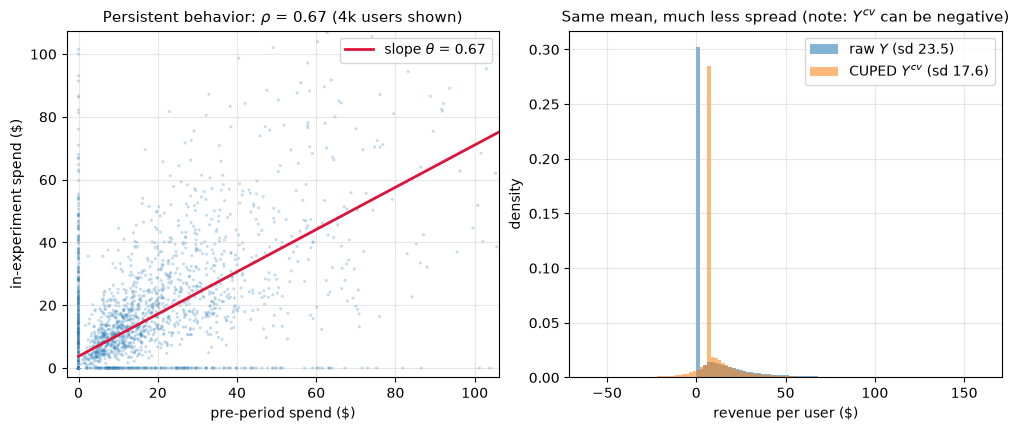

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4.2))

idx = rng.choice(N_USERS, 4000, replace=False)
ax = axes[0]
ax.scatter(x[idx], y[idx], s=5, alpha=0.25, edgecolors="none")
xs = np.linspace(0, np.quantile(x, 0.99), 100)
ax.plot(xs, y.mean() + theta * (xs - x.mean()), color="crimson", lw=2,
        label=f"slope $\\theta$ = {theta:.2f}")
ax.set(xlim=(-3, np.quantile(x, 0.99)), ylim=(-3, np.quantile(y, 0.99)),
       xlabel="pre-period spend ($)", ylabel="in-experiment spend ($)",
       title=f"Persistent behavior: $\\rho$ = {rho:.2f} (4k users shown)")
ax.legend()

ax = axes[1]
bins = np.linspace(-60, 160, 111)
ax.hist(y, bins=bins, density=True, alpha=0.55, label=f"raw $Y$ (sd {y.std(ddof=1):.1f})")
ax.hist(ycv, bins=bins, density=True, alpha=0.55,
        label=f"CUPED $Y^{{cv}}$ (sd {ycv.std(ddof=1):.1f})")
ax.set(xlabel="revenue per user ($)", ylabel="density",
       title="Same mean, much less spread (note: $Y^{cv}$ can be negative)")
ax.legend()
plt.show()

The right panel is the whole story: the adjusted metric keeps the mean (and the expected
treatment difference) but concentrates the distribution. $Y^{cv}$ is an *estimator
device*, not a real dollar amount — a pre-period whale who bought nothing this period gets
a negative adjusted value. That is fine: we only ever compare arm means of it. And note
the readout above: the same 200k users that missed the true effect at $p \approx 0.23$
now detect it at $p \approx 0.015$ — nothing changed except the variance.

### Cash value of the reduction

Re-run the Section 1 sizing with the adjusted metric's standard deviation.

In [6]:
sd_cv = ycv.std(ddof=1)
n_arm_cuped = n_per_arm(sd_cv, delta_target)
days_cuped = 2 * n_arm_cuped / DAILY_USERS
n_arm_14d = 14 * DAILY_USERS / 2

money = pd.DataFrame({
    "metric sd": [sd_y, sd_cv],
    "n per arm (2% MDE)": [n_arm_base, n_arm_cuped],
    "days @ 15k/day": [days_base, days_cuped],
    "MDE in a fixed 14 days": [mde_abs(sd_y, n_arm_14d) / ctrl_mean,
                               mde_abs(sd_cv, n_arm_14d) / ctrl_mean],
}, index=["difference in means", "CUPED"])
money["n per arm (2% MDE)"] = money["n per arm (2% MDE)"].round(0)
print(money.round(3).to_string())

print(f"\nSame question answered {days_base - days_cuped:.1f} days sooner "
      f"({1 - days_cuped / days_base:.0%} less traffic),")
print(f"or a {mde_abs(sd_cv, n_arm_14d) / mde_abs(sd_y, n_arm_14d) - 1:+.0%} change in MDE "
      f"on a fixed 14-day slot.")
print(f"Experiment slots per year on this surface: {365 / days_base:.0f} -> {365 / days_cuped:.0f}")

                     metric sd  n per arm (2% MDE)  days @ 15k/day  MDE in a fixed 14 days
difference in means     23.528            176584.0          23.545                   0.026
CUPED                   17.570             98467.0          13.129                   0.019

Same question answered 10.4 days sooner (44% less traffic),
or a -25% change in MDE on a fixed 14-day slot.
Experiment slots per year on this surface: 16 -> 28


That is the answer to "how much money does variance reduction save": the platform either
runs ~75% more experiments per year on the same traffic, or detects effects
~25% smaller at the same cadence — compounding across every team, every quarter. This is
why CUPED is not an optional nicety but default infrastructure at scale.

## 3. Does it replicate? 1,200 experiments

One lucky experiment proves nothing (that is the lesson of
[01_statistical_foundations/01_sampling_clt_bootstrap.ipynb](../01_statistical_foundations/01_sampling_clt_bootstrap.ipynb)).
We re-run the whole pipeline 1,200 times at a smaller scale (10k users, +8% true effect so
that power differences are visible) and check three claims:

1. Both estimators are **unbiased** (sampling distributions centered on the truth).
2. CUPED's sampling SD shrinks by the predicted $\sqrt{1-\rho^2}$.
3. That shrinkage buys real **power** at $\alpha = 0.05$.

In [7]:
def replicate(n_sims, n, rel_effect, rng, bad_covariate=False):
    rows = []
    for _ in range(n_sims):
        g = gen_arrays(n, rel_effect, rng)
        yy, tt = g["spend_exp"], g["treatment"]
        e0, s0 = dim(yy, tt)
        ycv_, _ = cuped_adjust(yy, g["spend_pre"])
        e1, s1 = dim(ycv_, tt)
        row = dict(diff_means=e0, se_dm=s0, cuped=e1, se_cuped=s1)
        if bad_covariate:  # CUPED on an IN-experiment covariate (Section 7)
            ybad_, _ = cuped_adjust(yy, g["sessions_exp"].astype(float))
            e2, s2 = dim(ybad_, tt)
            row.update(cuped_bad=e2, se_bad=s2)
        rows.append(row)
    return pd.DataFrame(rows)


REP_EFFECT = 0.08
TRUE_REP = REP_EFFECT * TRUE_CTRL_MEAN
reps = replicate(1200, 10_000, REP_EFFECT, rng)

summary = pd.DataFrame({
    "mean estimate": [reps.diff_means.mean(), reps.cuped.mean()],
    "true ATE": TRUE_REP,
    "SD of estimates": [reps.diff_means.std(ddof=1), reps.cuped.std(ddof=1)],
    "power @ 5%": [(reps.diff_means.abs() / reps.se_dm > 1.96).mean(),
                   (reps.cuped.abs() / reps.se_cuped > 1.96).mean()],
}, index=["difference in means", "CUPED"])
print(summary.round(3).to_string())
print(f"\nSD ratio CUPED/DM: {reps.cuped.std(ddof=1) / reps.diff_means.std(ddof=1):.3f}"
      f"   predicted sqrt(1 - rho^2) = {np.sqrt(1 - rho**2):.3f}")

                     mean estimate  true ATE  SD of estimates  power @ 5%
difference in means          0.909     0.885            0.476       0.452
CUPED                        0.904     0.885            0.361       0.699

SD ratio CUPED/DM: 0.758   predicted sqrt(1 - rho^2) = 0.747


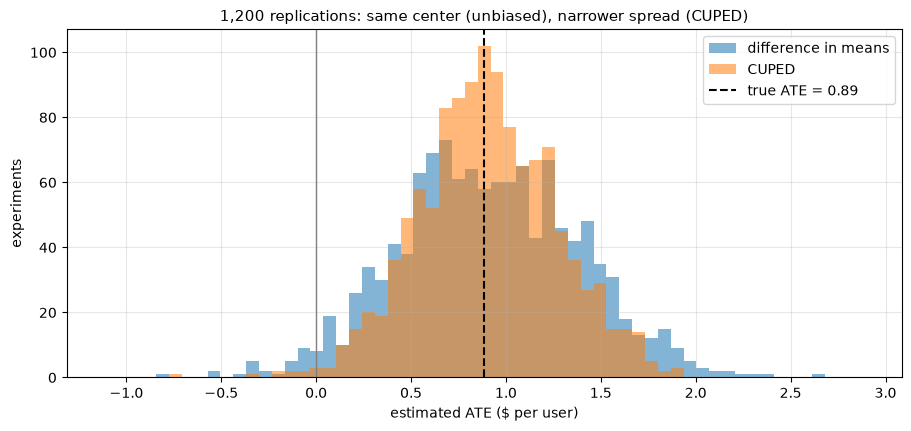

In [8]:
fig, ax = plt.subplots()
bins = np.linspace(TRUE_REP - 2.0, TRUE_REP + 2.0, 60)
ax.hist(reps.diff_means, bins=bins, alpha=0.55, label="difference in means")
ax.hist(reps.cuped, bins=bins, alpha=0.55, label="CUPED")
ax.axvline(TRUE_REP, color="k", ls="--", lw=1.5, label=f"true ATE = {TRUE_REP:.2f}")
ax.axvline(0, color="gray", lw=1)
ax.set(xlabel="estimated ATE ($ per user)", ylabel="experiments",
       title="1,200 replications: same center (unbiased), narrower spread (CUPED)")
ax.legend()
plt.show()

Both distributions sit on the truth; CUPED's is visibly tighter, with the SD ratio
within about a point of the predicted $\sqrt{1-\rho^2}$ and a material power gain
(~45% → ~70%) at identical traffic.

## 4. CUPED is regression adjustment (ANCOVA)

Run the regression

$$Y_i = \alpha + \tau\,T_i + \beta\,(X_i - \bar X) + \varepsilon_i$$

and $\hat\tau$ *is* the CUPED estimate, up to $O(1/n)$ terms: with $T \perp X$ under
randomization, the fitted $\hat\beta$ converges to $\mathrm{cov}(Y,X)/\mathrm{var}(X) =
\theta^*$, and partialling $X$ out of $Y$ is exactly the CUPED subtraction. The two
communities simply package it differently — check the numbers:

In [9]:
xc = x - x.mean()
ols1 = sm.OLS(y, sm.add_constant(np.column_stack([t, xc]))).fit(cov_type="HC1")

print("                       estimate        SE")
print(f"CUPED                  {est1:.5f}    {se1:.6f}")
print(f"OLS  y ~ T + x_c       {ols1.params[1]:.5f}    {ols1.bse[1]:.6f}   (HC1 robust)")
print(f"relative difference    {abs(ols1.params[1] / est1 - 1):.2e}      "
      f"{abs(ols1.bse[1] / se1 - 1):.2e}")

                       estimate        SE
CUPED                  0.19205    0.078573
OLS  y ~ T + x_c       0.19205    0.078606   (HC1 robust)
relative difference    4.54e-06      4.18e-04


Identical to several decimals. So why do platforms bother with the CUPED framing at all?
**Operations.** CUPED turns adjustment into a *metric transform*: compute $\theta$ once
per metric, store $Y^{cv}$ per user, and every existing piece of infrastructure —
scorecards, t-tests, SRM checks, segment cuts — works unchanged on the new column. A
regression per metric per experiment per segment is a much heavier dependency. When you
*are* in a regression mindset, though, you get upgrades for free:

- **Multiple covariates**: pre-period sessions and tenure carry signal about a user's
  propensity that pre-spend misses (a browser with 40 visits and \\$0 spend is not the
  same as a ghost with 0 visits) — add them as regressors.
- **Robust (HC) standard errors** come standard
  ([../01_statistical_foundations/03_regression_the_workhorse.ipynb](../01_statistical_foundations/03_regression_the_workhorse.ipynb)).
- **Lin (2013) interaction adjustment** ($T \times$ centered covariates) guards against
  efficiency loss with unequal arms or strong effect heterogeneity; with balanced arms it
  matches plain ANCOVA (Exercise 2).

In [10]:
sess_c = df["sessions_pre"].to_numpy() - df["sessions_pre"].mean()
ten_c = df["tenure_days"].to_numpy() - df["tenure_days"].mean()
ols2 = sm.OLS(y, sm.add_constant(np.column_stack([t, xc, sess_c, ten_c]))).fit(cov_type="HC1")

print(f"OLS + pre-spend:                    SE {ols1.bse[1]:.5f}  "
      f"(variance reduction {1 - (ols1.bse[1] / se0) ** 2:.1%})")
print(f"OLS + pre-spend, sessions, tenure:  SE {ols2.bse[1]:.5f}  "
      f"(variance reduction {1 - (ols2.bse[1] / se0) ** 2:.1%})")

OLS + pre-spend:                    SE 0.07861  (variance reduction 44.2%)
OLS + pre-spend, sessions, tenure:  SE 0.07781  (variance reduction 45.3%)


### CUPAC: let a model build the covariate

The logical endpoint: instead of hand-picking covariates, train an ML model to predict
$Y$ from **pre-experiment features only** and use the prediction $\hat Y_i = f(X_i)$ as
the single CUPED covariate (CUPAC — "control using predictions as covariates", popularized
by DoorDash). Any function of pre-experiment data is a valid covariate, so the estimate
stays unbiased; the better the prediction, the higher the $\rho$ and the bigger the
savings. Here the true $\mathbb{E}[Y \mid \text{user}]$ is a *product* of propensity and
basket size — a nonlinearity a GBM can in principle exploit and a linear model cannot.
Whether it *actually* beats a strong linear covariate at this sample size is an empirical
question, and the table below answers it honestly.

Two hygiene rules (same leakage logic as
[../04_ml_tabular/02_leakage_validation.ipynb](../04_ml_tabular/02_leakage_validation.ipynb)):
**features strictly pre-experiment**, and **cross-fit** so no user is scored by a model
that saw their own outcome. We go one step more conservative and train on control users
only, so the model cannot absorb any of the treatment effect.

In [11]:
def cupac_covariate(frame, features, target="spend_exp", n_splits=3):
    """Cross-fitted GBM prediction of the outcome from pre-experiment features.

    Models are trained on CONTROL users only; each control user is scored out-of-fold,
    treated users get the average prediction of the fold models.
    """
    X = frame[features].to_numpy(float)
    yv = frame[target].to_numpy(float)
    tv = frame["treatment"].to_numpy()
    ctrl_idx, trt_idx = np.flatnonzero(tv == 0), np.flatnonzero(tv == 1)
    pred = np.zeros(len(frame))
    trt_pred = np.zeros((n_splits, trt_idx.size))
    kf = KFold(n_splits=n_splits, shuffle=True, random_state=42)
    for i, (tr, te) in enumerate(kf.split(ctrl_idx)):
        m = LGBMRegressor(n_estimators=150, learning_rate=0.1, num_leaves=31,
                          min_child_samples=200, random_state=42, verbose=-1, n_jobs=1)
        m.fit(X[ctrl_idx[tr]], yv[ctrl_idx[tr]])
        pred[ctrl_idx[te]] = m.predict(X[ctrl_idx[te]])
        trt_pred[i] = m.predict(X[trt_idx])
    pred[trt_idx] = trt_pred.mean(axis=0)
    return pred


x_ml = cupac_covariate(df, ["spend_pre", "sessions_pre", "tenure_days"])
y_cupac, theta_ml = cuped_adjust(y, x_ml)
est_ml, se_ml = dim(y_cupac, t)

results = pd.DataFrame([
    ("difference in means", est0, se0),
    ("CUPED: pre-spend", est1, se1),
    ("OLS: + pre-spend", ols1.params[1], ols1.bse[1]),
    ("OLS: + pre-spend, sessions, tenure", ols2.params[1], ols2.bse[1]),
    ("CUPAC: LightGBM covariate", est_ml, se_ml),
], columns=["method", "estimate", "SE"]).set_index("method")
results["var reduction"] = 1 - (results["SE"] / se0) ** 2
results["traffic multiplier"] = (se0 / results["SE"]) ** 2
print(results.round(4).to_string())
print(f"\n(true ATE = {TRUE_ATE:.3f}; all rows should bracket it)")

                                    estimate      SE  var reduction  traffic multiplier
method                                                                                 
difference in means                   0.1254  0.1052         0.0000              1.0000
CUPED: pre-spend                      0.1920  0.0786         0.4424              1.7934
OLS: + pre-spend                      0.1921  0.0786         0.4419              1.7919
OLS: + pre-spend, sessions, tenure    0.1639  0.0778         0.4532              1.8288
CUPAC: LightGBM covariate             0.1565  0.0788         0.4391              1.7828

(true ATE = 0.221; all rows should bracket it)


All five methods target the same estimand and agree within noise; they differ only in
how much variance they remove — and here they barely differ at all. That is the honest
and, in practice, common result: the "same metric, pre-period" covariate already carries
most of the learnable signal, so the GBM **matches (~44%) but does not beat** the linear
adjustments. Zero-inflated, heavy-tailed outcomes are also exactly where squared-loss
boosting needs a lot of data to out-predict one strong linear covariate. The senior
takeaway: CUPAC's *guarantee* is validity, not gains — any function of pre-experiment
data is unbiased, so you can try the model risk-free and keep it only if the realized
$\rho$ improves. Its case is strongest when no single obvious pre-period twin of the
metric exists (new metrics, composite metrics, cold-start surfaces) — DoorDash's
motivating use case — where a few extra points of reduction over plain CUPED are typical.

## 5. Where CUPED shines vs where it does nothing

The savings are $\rho^2$, full stop:

| $\rho$ | 0.2 | 0.4 | 0.5 | 0.6 | 0.7 | 0.8 | 0.9 |
|---|---|---|---|---|---|---|---|
| variance reduction | 4% | 16% | 25% | 36% | 49% | 64% | 81% |

Below $\rho \approx 0.3$ CUPED is barely worth the pipeline. What drives $\rho$?

- **Metric persistence**: spend/engagement of *existing* users is sticky (high $\rho$);
  noisy or rare outcomes are not.
- **Pre-period window length**: a 1-week window is a noisy measurement of the user's
  underlying rate; averaging a longer window washes out week-to-week noise and raises
  $\rho$ — up to a ceiling set by how predictable the user is at all (the "oracle" that
  knows each user's true expected spend).
- **Matching windows**: the pre-metric should be the *same metric* over a comparable
  window — the best single covariate for 2-week revenue is (almost always) 2+ weeks of
  pre-revenue, not age or country.

 pre_weeks   rho  var_reduction
         1 0.410          0.168
         2 0.487          0.237
         4 0.543          0.295
         8 0.583          0.340
        12 0.597          0.356
oracle ceiling (true E[Y|user] as covariate): 39.9%


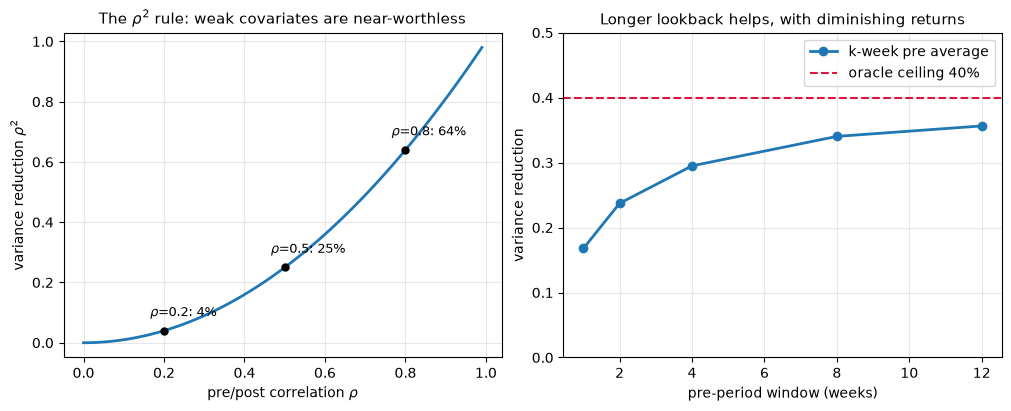

In [12]:
def window_sweep(weeks_list, n, rng):
    """Variance reduction from a k-week pre-period average (no incidence stickiness:
    isolates the window-length effect). Returns the sweep and the oracle ceiling."""
    pi = rng.beta(0.8, 1.2, n)
    mu = rng.lognormal(3.0, 0.8, n)
    yv = (rng.random(n) < pi) * mu * rng.gamma(6.0, 1 / 6.0, n)
    out = []
    for k in weeks_list:
        tot = np.zeros(n)
        for _ in range(k):
            tot += (rng.random(n) < pi) * mu * rng.gamma(6.0, 1 / 6.0, n)
        r = np.corrcoef(tot / k, yv)[0, 1]
        out.append((k, r, r * r))
    cap = np.corrcoef(pi * mu, yv)[0, 1] ** 2   # oracle: true E[Y | user]
    return pd.DataFrame(out, columns=["pre_weeks", "rho", "var_reduction"]), cap


sweep, cap = window_sweep([1, 2, 4, 8, 12], 150_000, rng)
print(sweep.round(3).to_string(index=False))
print(f"oracle ceiling (true E[Y|user] as covariate): {cap:.1%}")

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
rr = np.linspace(0, 0.99, 100)
axes[0].plot(rr, rr**2, lw=2)
for r0 in [0.2, 0.5, 0.8]:
    axes[0].plot(r0, r0**2, "ko", ms=5)
    axes[0].annotate(f"$\\rho$={r0}: {r0**2:.0%}", (r0, r0**2),
                     textcoords="offset points", xytext=(-10, 10), fontsize=9)
axes[0].set(xlabel="pre/post correlation $\\rho$", ylabel="variance reduction $\\rho^2$",
            title="The $\\rho^2$ rule: weak covariates are near-worthless")

axes[1].plot(sweep.pre_weeks, sweep.var_reduction, "o-", lw=2, label="k-week pre average")
axes[1].axhline(cap, color="crimson", ls="--", lw=1.5,
                label=f"oracle ceiling {cap:.0%}")
axes[1].set(xlabel="pre-period window (weeks)", ylabel="variance reduction",
            title="Longer lookback helps, with diminishing returns", ylim=(0, 0.5))
axes[1].legend()
plt.show()

### New users: the population CUPED cannot touch

The covariate does not exist for users who joined after the pre-period window — often
20–40% of experiment traffic on a growing product, and ~100% for onboarding experiments,
where CUPED is structurally useless. Three ways to handle a **mixed population** (30% new
users below):

1. **Zero-impute** $X$ for new users and run plain CUPED. Still unbiased (the imputed
   covariate is still pre-experiment), but one pooled $\theta$ is now a compromise
   between two different populations.
2. **Regression with a missingness indicator**: `y ~ T + x_filled + is_new`. The dummy
   absorbs the (large) mean difference between new and existing users.
3. **Stratified CUPED**: split by coverage, apply CUPED where $X$ exists, plain
   difference-in-means for new users, recombine with population weights
   $\hat\Delta = w_{\text{cov}}\hat\Delta_{\text{cov}} + w_{\text{new}}\hat\Delta_{\text{new}}$
   (variance adds with $w^2$). This also gives per-segment readouts for free.

What you must **not** do is silently analyze covered users only: that changes the
estimand from "effect on experiment traffic" to "effect on tenured users" — a different
(usually higher-spending) population.

In [13]:
def gen_mixed(n, new_frac, rel_effect, rng):
    n_new = int(n * new_frac)
    old = gen_arrays(n - n_new, rel_effect, rng)
    pi_n = rng.beta(0.5, 1.5, n_new)                 # new users buy less (mean 0.25)
    mu_n = rng.lognormal(3.0, 0.8, n_new)
    t_n = rng.permutation(np.arange(n_new) % 2)
    y_n = ((rng.random(n_new) < pi_n) * mu_n * rng.gamma(6.0, 1 / 6.0, n_new)
           * (1 + rel_effect * t_n))
    return pd.DataFrame({
        "treatment": np.concatenate([old["treatment"], t_n]),
        "spend_pre": np.concatenate([old["spend_pre"], np.full(n_new, np.nan)]),
        "spend_exp": np.concatenate([old["spend_exp"], y_n]),
        "is_new": np.concatenate([np.zeros(n - n_new, bool), np.ones(n_new, bool)]),
    })


dfm = gen_mixed(200_000, 0.30, REL_EFFECT, rng)
ym, tm = dfm["spend_exp"].to_numpy(), dfm["treatment"].to_numpy()
xm, new = dfm["spend_pre"].to_numpy(), dfm["is_new"].to_numpy()

TRUE_MIXED = REL_EFFECT * (0.7 * TRUE_CTRL_MEAN + 0.3 * 0.25 * np.exp(3.0 + 0.8**2 / 2))

e_na, s_na = dim(ym, tm)                                   # 1. no adjustment
x0 = np.nan_to_num(xm)
ycv0, _ = cuped_adjust(ym, x0)
e_im, s_im = dim(ycv0, tm)                                 # 2. zero-impute CUPED
Xr = sm.add_constant(np.column_stack([tm, x0 - x0.mean(), new - new.mean()]))
olsm = sm.OLS(ym, Xr).fit(cov_type="HC1")                  # 3. regression + dummy
cov = ~new                                                 # 4. stratified CUPED
ycv_c, _ = cuped_adjust(ym[cov], xm[cov])
e_c, s_c = dim(ycv_c, tm[cov])
e_n, s_n = dim(ym[new], tm[new])
w = cov.mean()
e_st = w * e_c + (1 - w) * e_n
s_st = np.sqrt(w**2 * s_c**2 + (1 - w) ** 2 * s_n**2)

mixed = pd.DataFrame([
    ("no adjustment", e_na, s_na),
    ("CUPED, zero-imputed X", e_im, s_im),
    ("OLS + X + is_new dummy", olsm.params[1], olsm.bse[1]),
    ("stratified CUPED", e_st, s_st),
], columns=["method", "estimate", "SE"]).set_index("method")
mixed["var reduction"] = 1 - (mixed["SE"] / s_na) ** 2
print(mixed.round(4).to_string())
print(f"\ntrue mixed-population ATE: {TRUE_MIXED:.3f}")
print(f"covered-users-only estimate: {e_c:.3f}  <- different estimand! "
      f"(their true ATE is {TRUE_ATE:.3f})")
print(f"for reference, reduction on a 100%-covered population was {var_red:.1%}")

                        estimate      SE  var reduction
method                                                 
no adjustment             0.0856  0.1015         0.0000
CUPED, zero-imputed X     0.1726  0.0822         0.3435
OLS + X + is_new dummy    0.1750  0.0820         0.3469
stratified CUPED          0.1750  0.0820         0.3474

true mixed-population ATE: 0.196
covered-users-only estimate: 0.178  <- different estimand! (their true ATE is 0.221)
for reference, reduction on a 100%-covered population was 44.2%


All four estimators are valid for the mixed-population ATE; the reduction is simply
**diluted** — the new-user stratum contributes its variance untouched, so ~44% on covered
users becomes ~35% overall. The covered-only number answers a different question: its
target is the tenured-user ATE ($0.22), not the all-traffic ATE ($0.20) — tenured users
spend more, so the same relative lift is a larger absolute effect. In a platform,
stratified CUPED (or the dummy regression) is the standard answer, and the coverage rate
is a metric worth monitoring per experiment.

## 6. Post-stratification, and why binary metrics resist

**Post-stratification** is variance reduction with a *categorical* covariate: estimate
the effect within strata $s$ (defined by pre-experiment attributes), then average with
population weights $w_s = n_s / n$:

$$\hat\Delta_{ps} = \sum_s w_s\,\bigl(\bar Y_{1s} - \bar Y_{0s}\bigr), \qquad
\widehat{\mathrm{var}} = \sum_s w_s^2\,\widehat{\mathrm{var}}(\hat\Delta_s).$$

It removes the between-strata component of variance — mechanically the same trick as
CUPED with stratum dummies (equivalently, ANCOVA on a discretized covariate). Comparing
on the same experiment: binning pre-spend ever finer approaches, but cannot beat, the
linear adjustment, because binning throws away within-bin detail. Post-stratification
earns its keep when the natural covariate *is* categorical (platform, country, tier),
when robustness to a nonlinear $Y$–$X$ link matters more than the last point of
variance, or when done at *design time* (blocked randomization).

In [14]:
def post_stratified(yv, tv, strata):
    est = var = 0.0
    for s in np.unique(strata):
        m = strata == s
        e, se = dim(yv[m], tv[m])
        w_s = m.mean()
        est += w_s * e
        var += w_s**2 * se**2
    return est, np.sqrt(var)


def spend_strata(pre, n_bins):
    """Stratum ids: -1 for zero pre-spend, else quantile bin of positive pre-spend."""
    lab = pd.qcut(pd.Series(pre).where(pre > 0), n_bins, labels=False)
    return lab.fillna(-1).astype(int).to_numpy()


rows = [("difference in means", est0, se0)]
for name, strata in [
    ("2 strata: pre-buyer y/n", (x > 0).astype(int)),
    ("5 strata: zero + quartiles", spend_strata(x, 4)),
    ("11 strata: zero + deciles", spend_strata(x, 10)),
    ("21 strata: zero + 20 bins", spend_strata(x, 20)),
]:
    e, s = post_stratified(y, t, strata)
    rows.append((name, e, s))
rows.append(("CUPED (linear covariate)", est1, se1))

ps = pd.DataFrame(rows, columns=["method", "estimate", "SE"]).set_index("method")
ps["var reduction"] = 1 - (ps["SE"] / se0) ** 2
print(ps.round(4).to_string())

                            estimate      SE  var reduction
method                                                     
difference in means           0.1254  0.1052         0.0000
2 strata: pre-buyer y/n       0.1467  0.0952         0.1823
5 strata: zero + quartiles    0.1703  0.0849         0.3490
11 strata: zero + deciles     0.1739  0.0818         0.3953
21 strata: zero + 20 bins     0.1730  0.0806         0.4132
CUPED (linear covariate)      0.1920  0.0786         0.4424


### Binary metrics: a hard ceiling on the help

For a binary outcome (conversion) with user-level propensity $p_i$, the law of total
variance splits the metric variance into

$$\mathrm{var}(Y) = \underbrace{\mathbb{E}[\,p_i(1-p_i)\,]}_{\text{coin-flip noise: irreducible}}
\;+\; \underbrace{\mathrm{var}(p_i)}_{\text{between-user: the only part any covariate can explain}}.$$

No covariate — not even an oracle handing you each user's true $p_i$ — can touch the
Bernoulli term. So the *ceiling* on variance reduction is $\mathrm{var}(p_i)/\mathrm{var}(Y)$,
and a realistic covariate (last period's 0/1 conversion) achieves far less, because a
single binary observation is itself a terrible measurement of $p_i$. For rare events the
ceiling collapses: propensities all sit near zero, so $\mathrm{var}(p_i)$ is tiny
relative to $p(1-p)$. Compare a frequent, persistent action against a rare conversion:

In [15]:
def binary_profile(a, b, lift, n, rng, weeks=(1, 4, 8)):
    """rho^2 (= CUPED variance reduction) for k-week pre-conversion covariates."""
    pi = rng.beta(a, b, n)
    tv = rng.permutation(np.arange(n) % 2)
    yb = (rng.random(n) < np.clip(pi + lift * tv, 0, 1)).astype(float)
    out = {"base rate": yb[tv == 0].mean()}
    for k in weeks:
        xk = rng.binomial(k, pi) / k
        out[f"{k}-week pre covariate"] = np.corrcoef(xk, yb)[0, 1] ** 2
    out["oracle ceiling (true p_i)"] = np.corrcoef(pi, yb)[0, 1] ** 2
    return pd.Series(out), yb, tv, rng.binomial(1, pi).astype(float)


prof_c, yb, tb, xb = binary_profile(0.8, 1.2, 0.008, 300_000, rng)   # weekly purchase
prof_r, *_ = binary_profile(0.5, 12.0, 0.002, 300_000, rng)          # rare conversion

binary_tbl = pd.DataFrame({"weekly purchase (persistent)": prof_c,
                           "rare conversion": prof_r})
print(binary_tbl.round(4).to_string())

ycv_b, _ = cuped_adjust(yb, xb)
_, se_b_raw = dim(yb, tb)
_, se_b_cv = dim(ycv_b, tb)
print(f"\nCUPED on the purchase-rate metric (1-week covariate): "
      f"SE {se_b_raw:.5f} -> {se_b_cv:.5f}  ({1 - se_b_cv / se_b_raw:.1%} CI shrinkage)")
print(f"vs the continuous spend metric earlier: {1 - se1 / se0:.1%} CI shrinkage")

                           weekly purchase (persistent)  rare conversion
base rate                                        0.4008           0.0400
1-week pre covariate                             0.1123           0.0056
4-week pre covariate                             0.2220           0.0177
8-week pre covariate                             0.2659           0.0296
oracle ceiling (true p_i)                        0.3336           0.0726

CUPED on the purchase-rate metric (1-week covariate): SE 0.00179 -> 0.00169  (5.7% CI shrinkage)
vs the continuous spend metric earlier: 25.3% CI shrinkage


Read the table bottom-up: even the **oracle** tops out around a third of the variance for
the frequent action and single-digit percent for the rare conversion; a realistic 1-week
binary covariate manages ~11% and ~0.5% respectively. This is why platform teams report
CUPED savings of 40–60% on revenue/engagement metrics but only a few percent on
conversion — and why for rare binary outcomes your effort is better spent on more traffic,
a more sensitive proxy metric, or a longer pre-window (Exercise 3 quantifies the window
effect analytically).

## 7. Pitfalls

### Pitfall 1 — the classic bug: an in-experiment covariate

The single most damaging CUPED mistake: using a covariate measured **during** the
experiment. It usually happens innocently — "sessions this period correlates with revenue
at 0.5, let's adjust for it!" — and it is seductive because the variance *does* go down.
But if the treatment moves the covariate (here: the new checkout also lifts sessions by
5%), the adjustment subtracts part of the treatment effect itself:
$\mathbb{E}[\bar X_1] - \bar{\mathbb{E}}[\bar X_0] \ne 0$, so the cancellation that made
CUPED unbiased is gone, and the bias is $-\theta\,(\mathbb{E}[\bar X_1]-\mathbb{E}[\bar X_0])$.
This is precisely "conditioning on a post-treatment variable" from
[../03_causal_inference/01_potential_outcomes_dags.ipynb](../03_causal_inference/01_potential_outcomes_dags.ipynb).
No diagnostic on a single experiment will flag it — the readout just comes back smaller
and more "precise". Replication with known truth exposes it:

                                 mean estimate  true ATE   bias  SD of estimates
CUPED, PRE-experiment covariate          0.863     0.885 -0.022            0.373
CUPED, IN-experiment covariate           0.305     0.885 -0.580            0.452

bias as share of the true effect: -65%


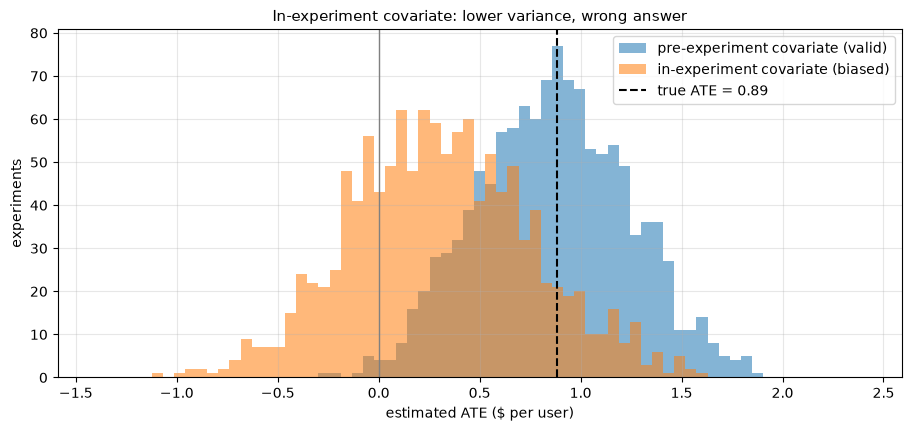

In [16]:
reps_bad = replicate(1200, 10_000, REP_EFFECT, rng, bad_covariate=True)

bad_summary = pd.DataFrame({
    "mean estimate": [reps_bad.cuped.mean(), reps_bad.cuped_bad.mean()],
    "true ATE": TRUE_REP,
    "bias": [reps_bad.cuped.mean() - TRUE_REP, reps_bad.cuped_bad.mean() - TRUE_REP],
    "SD of estimates": [reps_bad.cuped.std(ddof=1), reps_bad.cuped_bad.std(ddof=1)],
}, index=["CUPED, PRE-experiment covariate", "CUPED, IN-experiment covariate"])
print(bad_summary.round(3).to_string())
print(f"\nbias as share of the true effect: "
      f"{(reps_bad.cuped_bad.mean() - TRUE_REP) / TRUE_REP:+.0%}")

fig, ax = plt.subplots()
bins = np.linspace(-1.4, 2.4, 70)
ax.hist(reps_bad.cuped, bins=bins, alpha=0.55, label="pre-experiment covariate (valid)")
ax.hist(reps_bad.cuped_bad, bins=bins, alpha=0.55, label="in-experiment covariate (biased)")
ax.axvline(TRUE_REP, color="k", ls="--", lw=1.5, label=f"true ATE = {TRUE_REP:.2f}")
ax.axvline(0, color="gray", lw=1)
ax.set(xlabel="estimated ATE ($ per user)", ylabel="experiments",
       title="In-experiment covariate: lower variance, wrong answer")
ax.legend()
plt.show()

The bad estimator throws away roughly two-thirds of the true effect — enough to kill a
winning launch — while looking *tighter* than the honest one. If the treatment had *reduced*
engagement while lifting revenue, the bias would run the other way and manufacture a
false win. The rule is absolute: **the covariate must be fixed before randomization**
(or provably unaffected by treatment, which you cannot prove from the experiment itself).

### Pitfall 2 — a data glitch in the pre-period wastes the adjustment (but cannot bias it)

$\theta = \mathrm{cov}(Y,X)/\mathrm{var}(X)$ has $\mathrm{var}(X)$ in the denominator: one
corrupted pre-period value (a currency-cents ingestion bug, a bot) explodes
$\mathrm{var}(X)$, drives $\theta \to 0$, and silently switches CUPED off. Because $X$ is
pre-experiment, the estimate stays *unbiased* — you lose efficiency, not validity — and
winsorizing the covariate is always safe (any transform of pre-experiment data is a valid
covariate). Winsorize by default.

In [17]:
g = gen_arrays(20_000, REL_EFFECT, rng)
yw, xw, tw = g["spend_exp"], g["spend_pre"], g["treatment"]

xw_bug = xw.copy()
xw_bug[np.flatnonzero(tw == 0)[0]] = 2_000_000.0        # one $20k order logged in cents
xw_fix = np.minimum(xw_bug, np.quantile(xw_bug, 0.999))  # winsorize at p99.9

rows = []
for name, xv in [("clean pre-period", xw), ("with corrupted value", xw_bug),
                 ("corrupted, winsorized", xw_fix)]:
    ycv_w, th = cuped_adjust(yw, xv)
    e, s = dim(ycv_w, tw)
    rows.append((name, th, 1 - ycv_w.var(ddof=1) / yw.var(ddof=1), e, s))
whale = pd.DataFrame(rows, columns=["covariate", "theta", "var reduction",
                                    "estimate", "SE"]).set_index("covariate")
print(whale.round(4).to_string())

                        theta  var reduction  estimate      SE
covariate                                                     
clean pre-period       0.7496         0.4300    0.1647  0.2852
with corrupted value  -0.0000         0.0000    0.4010  0.3777
corrupted, winsorized  0.7435         0.3925    0.1809  0.2944


### Pitfall 3 — expecting CUPED to fix things it cannot fix

CUPED changes exactly one thing: variance. It does **not**:

- Fix **bias**: an SRM ([01_ab_test_end_to_end.ipynb](./01_ab_test_end_to_end.ipynb)), a
  broken bucketing pipeline, or novelty effects pass through untouched — now with tighter
  CIs around the wrong number. Run the same validity checks.
- License **peeking**: the adjusted metric is still a fixed-horizon test statistic; if you
  look daily you need sequential machinery
  ([04_peeking_sequential.ipynb](./04_peeking_sequential.ipynb)). (CUPED *composes* with
  it — variance reduction makes sequential tests cross their boundaries sooner.)
- Transfer to **ratio metrics** without care: for revenue-per-session or CTR the unit of
  analysis is not the unit of randomization, so the adjustment and its SE both need the
  delta method ([05_ratio_metrics_delta_method.ipynb](./05_ratio_metrics_delta_method.ipynb)).
- Rescue an experiment with **no usable pre-period** — onboarding flows, brand-new
  surfaces. There the answer is design (bigger MDE, longer test, proxy metrics), not
  adjustment.

## Interview corner

**1. "Explain CUPED to a PM in two sentences."**
We already know a lot about each user before the test starts — last month's spend
predicts this month's. CUPED measures each user's result *relative to what we'd have
predicted from their history* — like a golf handicap — so the persistent
whale-vs-non-buyer differences stop drowning out the treatment signal, and we get the
same answer with ~44% less traffic. Nothing about the metric definition or the decision
changes.

**2. "Why must the covariate be pre-experiment?"**
Randomization makes anything determined before assignment independent of the arm, so the
adjustment has equal expectation in both arms and cancels from the difference — unbiased
for any $\theta$. Anything measured after assignment can carry treatment effect; adjusting
for it subtracts effect (bias $= -\theta\,\Delta_X$), i.e., conditioning on a
post-treatment variable / a "bad control". Strong answer adds: the failure is invisible in
a single experiment because variance still shrinks.

**3. "CUPED vs regression adjustment — what's the difference?"**
Same estimator: CUPED with $\theta = \mathrm{cov}/\mathrm{var}$ is OLS
`y ~ T + centered x` up to $O(1/n)$. CUPED is the operational packaging — one adjusted
metric column, reusable by all existing t-test/scorecard infrastructure across hundreds of
metrics. Regression is the statistical generalization — multiple covariates, robust SEs,
Lin interactions for unequal arms. Mention CUPAC as the ML endpoint: any function of
pre-experiment data is a valid covariate, so let a model build the best one, cross-fitted.

**4. "How much money does variance reduction actually save?"**
Traffic and time scale with variance: reduction $\rho^2$ means $1/(1-\rho^2)\times$
effective traffic. Concrete: $\rho = 0.66$ on our revenue metric → 44% less traffic →
a 24-day test finishes in 13, or ~75% more experiments per year through the same surface,
or a 25% smaller MDE at fixed duration. At a company running thousands of experiments,
that compounds into the single highest-ROI piece of experimentation infrastructure.

**5. "When would you tell a team CUPED won't help?"**
Low pre/post correlation: new users with no history (onboarding funnels), rare binary
conversions (the $\mathrm{var}(p_i)$ ceiling), inherently volatile metrics, or a
pre-period window that's too short or mismatched. Quote the $\rho^2$ rule: $\rho = 0.3$
saves 9% — not worth the pipeline complexity on its own.

**6. "A teammate proposes adjusting for in-experiment engagement to tighten CIs. Response?"**
Refuse and explain: treatment plausibly moves engagement, so the adjustment eats part of
the effect; show the bias formula and offer the valid alternatives — pre-experiment
engagement, or a pre-experiment ML prediction of engagement (CUPAC).

**7. "How do you productionize CUPED?"**
Nightly job snapshots per-user pre-period aggregates *at assignment time* (frozen
thereafter); $\theta$ per metric per experiment computed pooled; winsorize covariates;
strata/dummy fallback for uncovered users and monitor the coverage rate; log realized
variance reduction per experiment so teams see the savings and trust the system.

## Key takeaways

- Variance is the only sizing lever you can engineer without changing the question;
  reduction $f$ ⇒ $f$ less traffic/time at the same $\alpha$, power, and MDE.
- CUPED: $Y^{cv} = Y - \theta(X - \bar X)$ with $\theta^* = \mathrm{cov}(Y,X)/\mathrm{var}(X)$;
  variance falls by $\rho^2$, CIs shrink by $\sqrt{1-\rho^2}$, effective traffic
  multiplies by $1/(1-\rho^2)$.
- Unbiasedness needs exactly one thing: the covariate is **pre-experiment**, hence
  independent of assignment. Any function of pre-experiment data qualifies — including an
  ML prediction (CUPAC, cross-fitted).
- CUPED ≡ ANCOVA numerically; choose the framing by operational needs, and use regression
  when you want multiple covariates or robust/interacted variants.
- The best covariate is usually the same metric over a longer pre-window; gains have a
  ceiling at the user-level predictability of the metric.
- Mixed populations: stratify on covariate coverage (CUPED where it exists, plain
  difference elsewhere); never quietly drop new users — that changes the estimand.
- Post-stratification = coarse CUPED; great for genuinely categorical covariates and
  design-time blocking, slightly weaker than the linear adjustment on a continuous one.
- Binary metrics: reduction is capped at $\mathrm{var}(p_i)/\mathrm{var}(Y)$ — modest for
  frequent actions, negligible for rare conversions.
- The in-experiment covariate bug shrinks variance *and* biases the estimate — the extra
  precision makes it more convincing, not more correct.

## Exercises

**Exercise 1.** A checkout experiment gets 8,000 users/day (both arms combined). Revenue
per user: mean \\$9.50, sd \\$18. Target: 3% relative MDE, $\alpha = 0.05$, power 80%.
(a) How many days without variance reduction? (b) With CUPED at $\rho = 0.55$?
(c) What $\rho$ would fit the experiment into 14 days?

In [18]:
# --- Solution ---
mean_r, sd_r, daily = 9.50, 18.0, 8_000
delta_r = 0.03 * mean_r

n_a = n_per_arm(sd_r, delta_r)
days_a = 2 * n_a / daily
days_b = days_a * (1 - 0.55**2)
# (c) need total 14*daily users -> variance factor f = 14 / days_a -> rho = sqrt(1 - f)
f_needed = 14 / days_a
rho_needed = np.sqrt(1 - f_needed)
print(f"(a) n/arm = {n_a:,.0f} -> {days_a:.1f} days")
print(f"(b) at rho = 0.55: {days_b:.1f} days")
print(f"(c) need variance factor {f_needed:.3f} -> rho = {rho_needed:.2f} "
      f"(a modest correlation already fits the slot)")

(a) n/arm = 62,617 -> 15.7 days
(b) at rho = 0.55: 10.9 days
(c) need variance factor 0.894 -> rho = 0.33 (a modest correlation already fits the slot)


**Exercise 2.** On the Section 1 dataset, show numerically that four estimators agree to
within a tiny fraction of the SE: (i) CUPED with pooled $\theta$, (ii) CUPED with
$\theta$ estimated on the **control arm only** (a common production variant — immune to
the treatment slightly distorting the pooled covariance), (iii) OLS `y ~ T + x_c`, and
(iv) Lin's estimator (OLS with `T` interacted with the centered covariate).

In [19]:
# --- Solution ---
theta_ctrl = (np.cov(y[t == 0], x[t == 0], ddof=1)[0, 1] / np.var(x[t == 0], ddof=1))
e_ii, s_ii = dim(y - theta_ctrl * (x - x.mean()), t)

X_lin = sm.add_constant(np.column_stack([t, xc, t * xc]))   # Lin (2013)
lin = sm.OLS(y, X_lin).fit(cov_type="HC1")

ex2 = pd.DataFrame([
    ("CUPED, pooled theta", est1, se1),
    ("CUPED, control-only theta", e_ii, s_ii),
    ("OLS y ~ T + x_c", ols1.params[1], ols1.bse[1]),
    ("Lin: OLS y ~ T * x_c", lin.params[1], lin.bse[1]),
], columns=["estimator", "estimate", "SE"]).set_index("estimator")
print(ex2.round(5).to_string())
spread = ex2["estimate"].max() - ex2["estimate"].min()
print(f"\nmax spread between estimates: {spread:.4f} = {spread / se1:.1%} of one SE")
print(f"(thetas: pooled {theta:.3f} vs control-only {theta_ctrl:.3f})")

                           estimate       SE
estimator                                   
CUPED, pooled theta         0.19205  0.07857
CUPED, control-only theta   0.19100  0.07858
OLS y ~ T + x_c             0.19205  0.07861
Lin: OLS y ~ T * x_c        0.19207  0.07861

max spread between estimates: 0.0011 = 1.4% of one SE
(thetas: pooled 0.673 vs control-only 0.663)


With balanced arms and a small effect, all four coincide for practical purposes; Lin's
version is the safe default when arms are unequal or heterogeneity is strong.

**Exercise 3.** For the persistent binary action ($p_i \sim \mathrm{Beta}(0.8, 1.2)$,
weekly conversions i.i.d. Bernoulli($p_i$) given $p_i$), derive the variance reduction
from using a $k$-week pre-period average as the covariate, and find the smallest $k$
achieving at least 20%. *Hint:* $\rho_k^2 =
\mathrm{var}(p_i)^2 \big/ \bigl[\bigl(\mathrm{var}(p_i) + \mathbb{E}[p_i(1-p_i)]/k\bigr)\,\mathrm{var}(Y)\bigr]$.

In [20]:
# --- Solution ---
# Beta(0.8, 1.2): E[p] = 0.4, var(p) = ab/((a+b)^2 (a+b+1)) = 0.08, E[p(1-p)] = 0.16
vp, ep1p = 0.08, 0.16
var_y_bin = vp + ep1p                      # law of total variance = 0.24


def reduction_k(k):
    return vp**2 / ((vp + ep1p / k) * var_y_bin)


ks = np.arange(1, 9)
analytic = pd.Series([reduction_k(k) for k in ks], index=ks, name="analytic reduction")
print(analytic.round(3).to_string())
k_star = int(ks[np.argmax(analytic.to_numpy() >= 0.20)])
print(f"\nsmallest k with >= 20% reduction: k = {k_star}")

# simulation check at k = k_star
n_s = 300_000
p_i = rng.beta(0.8, 1.2, n_s)
y_s = (rng.random(n_s) < p_i).astype(float)
x_s = rng.binomial(k_star, p_i) / k_star
print(f"simulated rho^2 at k = {k_star}: {np.corrcoef(x_s, y_s)[0, 1] ** 2:.3f}")

1    0.111
2    0.167
3    0.200
4    0.222
5    0.238
6    0.250
7    0.259
8    0.267

smallest k with >= 20% reduction: k = 3


simulated rho^2 at k = 3: 0.199


The formula makes the diminishing returns explicit: the $\mathbb{E}[p(1-p)]/k$ term is
measurement noise on the covariate and dies off like $1/k$, but the ceiling
$\mathrm{var}(p)/\mathrm{var}(Y) = 33\%$ never moves. Three weeks of history already
clears 20% here — but only because this action is frequent and persistent; rerun the
numbers with the rare-conversion parameters from Section 6 and no realistic window gets
you anywhere.